<a href="https://colab.research.google.com/github/fadilaha/Ising-Model-on-Social-Opinion-Dynamic/blob/main/For_Research_HeatBath_AB_BC_Residual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#__Heat-Bath Dynamics with A-B Model Transition Rules and Blume-Capel Resistance Model__

This model has updated the rules of spin transition, adopting the A-B Model-inspired rules.  
__Transition Rules__  
*   +1 -> {+1, 0}; +1 can maintains its state or moves to 0  
*   0 -> {+1, 0, -1}; 0 can maintains its state or moves to +1 and -1  
*   -1 -> {0, -1}; -1 can maintains its state or moves to 0
*   Both +1 and -1 need to pass through 0 state first before transitioning to its opposites.  
In this logic, +1 and -1 can choose 0, and later:
1. Maintain its 0 state
2. Move to its opposite
3. Go back to its initial state  
The decision depends on the randomly drawn state by the system, based on the calculated probabilities for each possible states  

__The Probabilities__  

Just like the previous Heat-Bath Dynamics, for each selected spin, the probabilities of the three possible states are calculated based on their corresponding energies E($s'_i$) under the current effective field.  

$h_{eff}$ =  $h + JqM$  

$E(s'_i)$ = $-s'_i$($h_{eff}$) + $Ds'^2_i$  
where,  
$s'_i$ : possible new states of chosen spin  
$D$ : resistance parameter. It has negative value shows tendencies to maintain its non-neutral state.  

Boltzmann weight, $w($s'_i$) = e^{\frac{-E(s'_i)}{kB.T}}$  

Probability of a new state, $P($s'_i$) = {\frac{e^{\frac{-E(s'_i)}{kB.T}}}{(\sum_{s'_i} {w(s'_i)}}}$ ; $s'_i$ = {possible new state of the current chosen spin}

The system will draw a new state by randomly choose one element from possible_states. However, each element's chance of being chosen equal to the corresponding value in the previously calculated probabilities.  

__State-dependent neutrality (Blume-Capel D)__  

$E(s'_i)$ = $-s'_i$($h_{eff}$) + $Ds'^2_i$  

In this model, $D$ is always negative (resistance to leaving +1/-1) and its size depends on the collective opinion.

With $D_{0}$ = $D_{initial}$ (negative) and $dM$ = the distance of $|M|$ from the threshold of its band:

| Condition | dM | D |
|---|---|---|
| \|M\| < 0.5 | – | D0 |
| 0.5 ≤ \|M\| ≤ 0.6 | \|M\| − 0.5 | D0·(1 + k·dM) |
| \|M\| > 0.6 | \|M\| − 0.6 | −exp(\|D0\| + dM) |

\begin{cases} D_0= -0.5, & |M| < 0.5 \\ D_0\,(1 + dM), & 0.5 \le |M| \le 0.6 \\ -e^{\left(|D_0| + |dM|\right)}, & 0.6 < |M| \end{cases}

The further the majority is past its threshold, the stronger the resistance (D more negative). When the majority weakens (|M| falls), dM shrinks and the resistance weakens. Positive and negative majorities are treated the same because the rule uses |M|.

D is computed once at the start of each Monte Carlo step from M at the end of the previous step, and held fixed during that step.


In [ ]:
#External Event Generator
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
# 1. PARAMETERS YOU CAN ADJUST
total_days = 250          # Total simulation period
appearance_interval = 10   # New event every 7 days
first_event_day = 5       # Day of the first event
fade_days = 10            # Influence fades until this event age
seed = 58                 # Change seed to randomize again

# Random field settings
min_amplitude = 0.1
max_amplitude = 0.5

# Probability of each field direction
p_positive = 0.4
p_negative = 0.4
p_neutral = 0.2

# 2. GENERATE EVENT APPEARANCE DAYS
appearance_days = np.arange(first_event_day, total_days, appearance_interval)

# 3. RANDOMIZE FIELD VALUES
rng = np.random.default_rng(seed)

# Random maximum amplitude for each event
amplitudes = rng.uniform(min_amplitude, max_amplitude, len(appearance_days))

# Randomly choose positive, negative, or neutral
directions = rng.choice([1, -1, 0], size=len(appearance_days), p=[p_positive, p_negative, p_neutral])

field_values = amplitudes * directions

# 4. SAVE RAW EVENT DATA
# Columns: appearance day, field value, fade day
events = np.column_stack((appearance_days, field_values, np.full(len(appearance_days), fade_days)))

np.save("raw_external_field.npy", events)

print("Appearance day | Field value | Fade day")
print("----------------------------------------")
for day, value, fade in events:
    print(f"{day:14.0f} | {value:11.3f} | {fade:8.0f}")

#files.download("raw_external_field.npy")

Appearance day | Field value | Fade day
----------------------------------------
             5 |       0.000 |       10
            15 |       0.452 |       10
            25 |      -0.197 |       10
            35 |       0.183 |       10
            45 |       0.438 |       10
            55 |       0.156 |       10
            65 |       0.222 |       10
            75 |       0.155 |       10
            85 |      -0.311 |       10
            95 |       0.000 |       10
           105 |       0.000 |       10
           115 |      -0.208 |       10
           125 |       0.480 |       10
           135 |      -0.269 |       10
           145 |      -0.204 |       10
           155 |       0.324 |       10
           165 |      -0.477 |       10
           175 |      -0.454 |       10
           185 |       0.000 |       10
           195 |      -0.183 |       10
           205 |       0.000 |       10
           215 |      -0.103 |       10
           225 |       0.000 |       10

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Load External Event Schedule Generated from the cell above
# The file can be found in the https://github.com/fadilaha/Ising-Model-on-Social-Opinion-Dynamic
external_events = np.load("raw_external_field.npy").tolist()
print("External events:", external_events)

def compute_D(M, Do, k, M_low=0.5, M_high=0.6):
    # State-dependent Blume-Capel resistance parameter (always <= 0).
    # dM = distance of |M| from the threshold of its band
    # |M| <  M_low            : D = Do
    # M_low <= |M| <= M_high  : dM = |M| - M_low ,  D = Do * (1 + k*dM)
    # |M| >  M_high           : dM = |M| - M_high,  D = -exp(|Do| + dM)

    absM = abs(M)
    if absM < M_low:
        return Do
    elif absM <= M_high:
        dM = absM - M_low
        return Do * (1 + k * dM)
    else:
        dM = absM - M_high
        return -np.exp(abs(Do) + dM)-(abs(Do/2)+dM)

def absorption(age, rise=(0.20, 0.30, 0.50), peak=0.80, fade_days=10, residual=0.10):
    # Fraction of ONE raw news event that the agents feel, 'age' days after publication.
    # day 0, 1, 2      : rise values (below 50%)
    # day 3            : peak (> 50%)
    # day 3..fade_days : exponential decay from the peak down to 1% of the peak
    # after fade_days  : 0 (fully gone)
    if age < 0 or age > fade_days:
        return 0.0
    if age < len(rise):
        return rise[int(age)]
    decay = -np.log(residual) / (fade_days - len(rise))
    return peak * np.exp(-decay * (age - len(rise)))

def simulate_open_population(N_up_initial, N_down_initial, N_o, T, h, J, q, Do, k_sensitivity,
                             r_growth, steps, external_events, M_low=0.5, M_high=0.6, dt=1.0,
                             rise=(0.20, 0.30, 0.50), peak=0.80, fade_days=10, residual=0.10):
    kB = 1
    # INITIAL POPULATION
    spins = ([1] * N_up_initial + [-1] * N_down_initial + [0] * N_o)
    np.random.shuffle(spins)
    N_up = N_up_initial
    N_down = N_down_initial
    N_neutral = N_o

    # DATA STORAGE
    Data_N_up = []
    Data_N_down = []
    Data_N_neutral = []
    Data_M = []
    Data_N_total = []
    Data_h_ext = []
    Data_h_felt = []
    Data_h_eff = []
    Data_D = []
    spin_history = []

    # INITIAL DATA
    N = len(spins)
    M = (N_up - N_down) / N

    Data_N_up.append(N_up)
    Data_N_down.append(N_down)
    Data_N_neutral.append(N_neutral)
    Data_M.append(M)
    Data_N_total.append(N)
    Data_h_ext.append(h)
    Data_h_felt.append(0.0)
    Data_h_eff.append(h + J * q * M)
    Data_D.append(compute_D(M, Do, k_sensitivity, M_low, M_high))
    spin_history.append(spins.copy())

    # MAIN SIMULATION
    for step in range(1, steps + 1):

        # 1. CALCULATE TOTAL EXTERNAL FIELD
        # 1a. h_ext = the news itself (decays to 1% after fade_days) -> only for plotting
        # 1b. h_felt = what the agents FEEL: each raw event weighted by the absorption profile

        h_ext = 0.0
        h_felt = 0.0

        for event_time, event_amplitude, event_fade_days in external_events:
            age = int(round(step - event_time))
            event_fade_days = int(event_fade_days)

            # Raw external field: exponential decay
            if 0 <= age <= event_fade_days:
                news_decay = np.log(100) / event_fade_days
                h_ext += event_amplitude * np.exp(-news_decay * age)

            # Absorbed external field: residual contribution
            h_felt += event_amplitude * absorption(age, rise=rise, peak=peak, fade_days=event_fade_days, residual=residual)

        ## 2. INTRINSIC GROWTH (TURNED OFF FOR THIS RESEARCH)
        #N = len(spins)
        #M = (N_up - N_down) / N

        ## dN/dt = r*N*M
        #dNdt = r_growth * N * M            #Intrinsic growth in one monte carlo sweep depends on the latest Magnetization value
        #dN = dNdt * dt

        ## Positive M -> new positive population
        #if dN > 0:
        #    new_population = int(np.floor(dN))
        #    if new_population > 0:
        #        spins.extend([1] * new_population)
        #        N_up += new_population

        ## Negative M -> new negative population
        #elif dN < 0:
        #    new_population = int(np.floor(abs(dN)))
        #    if new_population > 0:
        #        spins.extend([-1] * new_population)
        #        N_down += new_population

        ## Update total N and M after growth
        #N = len(spins)
        #M = (N_up - N_down) / N

        # 3. STATE-DEPENDENT D FOR THIS MONTE CARLO STEP
        # D depends on how far |M| (at the end of the previous MCS) is past its band threshold
        # D is computed once here and held fixed during the whole step
        M_prev = Data_M[-1]
        D = compute_D(M_prev, Do, k_sensitivity, M_low, M_high)

        # 4. HEAT-BATH SPIN DYNAMICS
        # N random spin-update attempts = 1 MCS
        for _ in range(N):
            # Current M
            M = (N_up - N_down) / N
            # Current mean-field effective field works on an individual
            h_eff = h + h_felt + J * q * M

            # Randomly choose one individual
            i = np.random.randint(0, N)
            sigma_old = spins[i]

            # TRANSITION RULE
            # +1 -> {+1, 0}; +1 can maintains its state or moves to 0
            #  0 -> {+1, 0, -1}; 0 can maintains its state or moves to +1 and -1
            # -1 -> {0, -1}; -1 can maintains its state or moves to 0
            # Both +1 and -1 need to pass through 0 state first before transitioning to its opposites.
            # In this logic, +1 and -1 can choose 0, and later:
            # (1) maintain its 0 state, (2) move to its opposite, (3) go back to its initial state
            # The decision depends on the randomly drawn state by the system, based on the calculated probabilities for each possible states.
            if sigma_old == 1:
                possible_states = np.array([1, 0])
            elif sigma_old == 0:
                possible_states = np.array([1, 0, -1])
            elif sigma_old == -1:
                possible_states = np.array([0, -1])

            # Heat-bath probabilities for allowed states
            energies = -possible_states * h_eff + D * possible_states**2     #Blume-Capel energy: field term + neutrality term
            weights = np.exp(np.clip(-energies / (kB * T), -100, 100))   #also calculate the boltzmann weights
            probabilities = weights / np.sum(weights)   #substitute the boltzmann weights (w) here to acquire the probability for each possibilities.
                                                        #probability = w/sum of w_i ; i= each possibilities for the chosen spin

            # Draw new state, randomly choose one element from possible_states
            # Each element's chance of being chosen equal to the corresponding value in the previously calculated probabilities
            sigma_new = np.random.choice(possible_states, p=probabilities)
            # Update the new chosen state
            if sigma_new != sigma_old:
                # Remove old state
                if sigma_old == 1:
                    N_up -= 1
                elif sigma_old == -1:
                    N_down -= 1
                elif sigma_old == 0:
                    N_neutral -= 1
                # Add new state
                if sigma_new == 1:
                    N_up += 1
                elif sigma_new == -1:
                    N_down += 1
                elif sigma_new == 0:
                    N_neutral += 1
            # Update spin
            spins[i] = sigma_new

        # 5. FINAL M AFTER THIS TIMESTEP
        M = (N_up - N_down) / N

        # Udpate Final effective field after Heat-Bath dynamics
        h_eff = h + h_felt + J * q * M

        # 6. STORE DATA
        Data_N_up.append(N_up)
        Data_N_down.append(N_down)
        Data_N_neutral.append(N_neutral)
        Data_M.append(M)
        Data_N_total.append(N)
        Data_h_ext.append(h_ext)
        Data_h_felt.append(h_felt)
        Data_h_eff.append(h_eff)
        Data_D.append(D)     # D that was used during this step
        spin_history.append(spins.copy())

        # PROGRESS
        if step % 10 == 0:
            print(f"MCS {step}/{steps} selesai | N = {N}")

    return (Data_N_up, Data_N_down, Data_N_neutral, Data_M, Data_N_total,
        Data_h_ext, Data_h_eff, Data_D, external_events, spin_history,
        Data_h_felt)

External events: [[5.0, 0.0, 10.0], [15.0, 0.45193344369230837, 10.0], [25.0, -0.19723658086288476, 10.0], [35.0, 0.18336818624614365, 10.0], [45.0, 0.43832517327880816, 10.0], [55.0, 0.15622918987473955, 10.0], [65.0, 0.22213301558859602, 10.0], [75.0, 0.15539247508876627, 10.0], [85.0, -0.3106288598640721, 10.0], [95.0, 0.0, 10.0], [105.0, 0.0, 10.0], [115.0, -0.2080198029652558, 10.0], [125.0, 0.4802186059675547, 10.0], [135.0, -0.2687780375356007, 10.0], [145.0, -0.2043493318213476, 10.0], [155.0, 0.32396978294955603, 10.0], [165.0, -0.4769702910159581, 10.0], [175.0, -0.4538509156265934, 10.0], [185.0, 0.0, 10.0], [195.0, -0.1826211687673073, 10.0], [205.0, 0.0, 10.0], [215.0, -0.10345769685397865, 10.0], [225.0, 0.0, 10.0], [235.0, -0.1367117796993983, 10.0], [245.0, 0.16473698168253464, 10.0]]


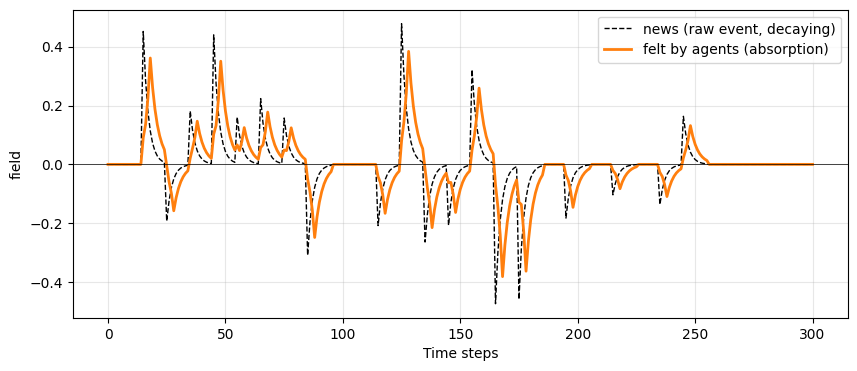

In [ ]:
#Show Absorbed External Field by Agents
plt.figure(figsize=(10, 4))
plt.plot(h_ext_history,  'k--', lw=1, label='news (raw event, decaying)')
plt.plot(h_felt_history, color='tab:orange', lw=2, label='felt by agents (absorption)')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel('Time steps'); plt.ylabel('field'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
#PARAMETER INPUT
N_up_initial = 3130
N_down_initial = 1319
N_o = 602

External_field = 0
J_coupling = 0.3
q_neighbors = 4

r_growth = 0
Temperature = 1.25
Time_steps = 300

#BLUME-CAPEL NEUTRALITY PARAMETER
#D is always negative here: resistance to leaving +1/-1
D_initial = -0.5    # baseline; Do = D_initial
k_sensitivity = 5      # middle band: Do*(1 + k*dM)
M_low = 0.5              # |M| <  M_low          -> D0
M_high = 0.6             # M_low <= |M| <= M_high -> D0*(1 + k*dM),   dM = |M| - M_low
                         # |M| > M_high           -> -exp(|D0| + dM), dM = |M| - M_high

np.random.seed(42)
#EXTERNAL EVENTS IS GENERATED ON GLAUBER'S NOTEBOOK, it has loaded in the simulation cell above

#RUN SIMULATION
results = simulate_open_population(N_up_initial, N_down_initial, N_o, Temperature, External_field, J_coupling,
    q_neighbors, D_initial, k_sensitivity, r_growth, Time_steps, external_events,
    M_low=M_low, M_high=M_high, dt=1.0)

(N_up_history, N_down_history, N_neutral_history, M_history, N_total_history,
    h_ext_history, h_eff_history, D_history, external_events, spin_history,
    h_felt_history) = results

MCS 10/300 selesai | N = 5051
MCS 20/300 selesai | N = 5051
MCS 30/300 selesai | N = 5051
MCS 40/300 selesai | N = 5051
MCS 50/300 selesai | N = 5051
MCS 60/300 selesai | N = 5051
MCS 70/300 selesai | N = 5051
MCS 80/300 selesai | N = 5051
MCS 90/300 selesai | N = 5051
MCS 100/300 selesai | N = 5051
MCS 110/300 selesai | N = 5051
MCS 120/300 selesai | N = 5051
MCS 130/300 selesai | N = 5051
MCS 140/300 selesai | N = 5051
MCS 150/300 selesai | N = 5051
MCS 160/300 selesai | N = 5051
MCS 170/300 selesai | N = 5051
MCS 180/300 selesai | N = 5051
MCS 190/300 selesai | N = 5051
MCS 200/300 selesai | N = 5051
MCS 210/300 selesai | N = 5051
MCS 220/300 selesai | N = 5051
MCS 230/300 selesai | N = 5051
MCS 240/300 selesai | N = 5051
MCS 250/300 selesai | N = 5051
MCS 260/300 selesai | N = 5051
MCS 270/300 selesai | N = 5051
MCS 280/300 selesai | N = 5051
MCS 290/300 selesai | N = 5051
MCS 300/300 selesai | N = 5051


__GRAPHS SECTION__

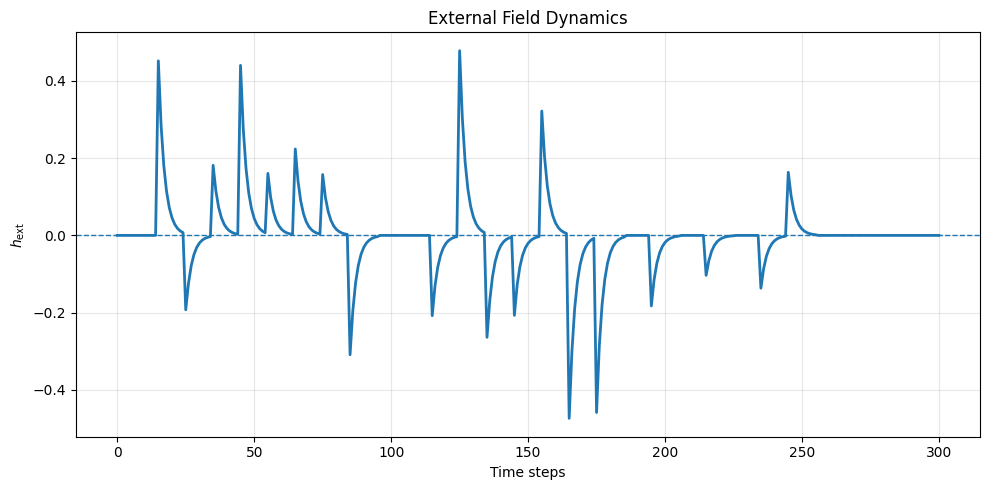

In [ ]:
#PLOT EXTERNAL FIELD EVENTS
time = np.arange(len(h_ext_history))
plt.figure(figsize=(10, 5))
plt.plot(
    time,
    h_ext_history,
    linewidth=2
)
plt.axhline(
    0,
    linestyle='--',
    linewidth=1
)
plt.xlabel("Time steps")
plt.ylabel(r"$h_{\mathrm{ext}}$")
plt.title("External Field Dynamics")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

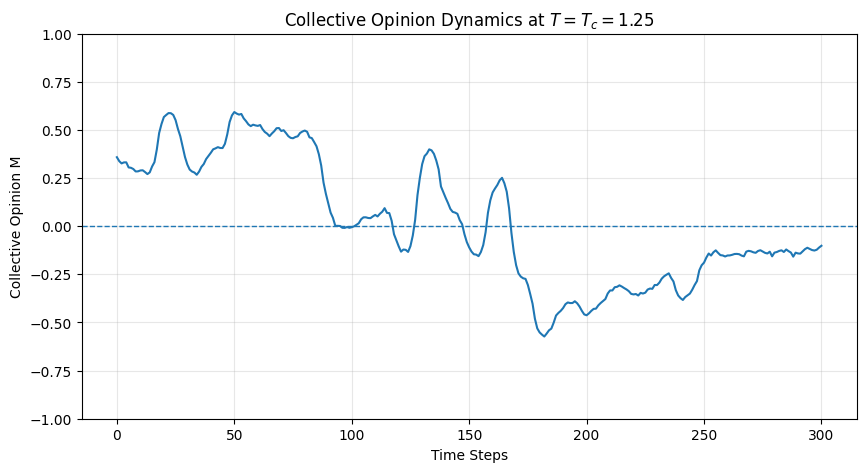

In [ ]:
# PLOT COLLECTIVE OPINION (M) OVER TIME
plt.figure(figsize=(10, 5))
plt.plot(M_history)
plt.axhline(
    0,
    linestyle='--',
    linewidth=1
)
plt.xlabel("Time Steps")
plt.ylabel("Collective Opinion M")
plt.title(f"Collective Opinion Dynamics at $T=T_c={Temperature}$")
plt.ylim(-1,1)
plt.grid(alpha=0.3)
plt.show()

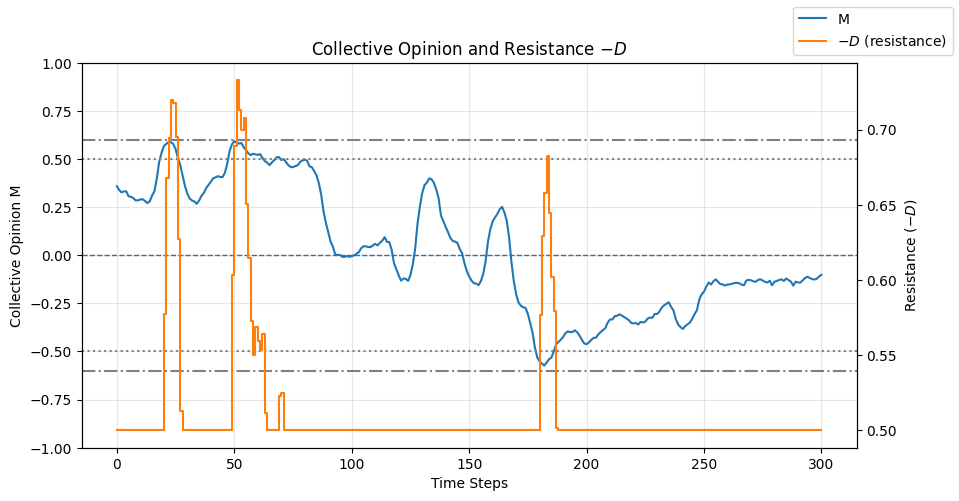

In [ ]:
# PLOT M TOGETHER WITH THE ACTIVE RESISTANCE (-D)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(M_history, label="M")
for thr in (M_low, -M_low):
    ax1.axhline(thr, linestyle=':', color='gray')
for thr in (M_high, -M_high):
    ax1.axhline(thr, linestyle='-.', color='gray')
ax1.axhline(0, linestyle='--', linewidth=1)
ax1.set_ylim(-1, 1)
ax1.set_xlabel("Time Steps")
ax1.set_ylabel("Collective Opinion M")

ax2 = ax1.twinx()
ax2.step(range(len(D_history)), -np.array(D_history), where='post',
         color='tab:orange', label=r"$-D$ (resistance)")
ax2.set_ylabel(r"Resistance $(-D)$")

fig.legend(loc="upper right")
plt.title(r"Collective Opinion and Resistance $-D$")
ax1.grid(alpha=0.3)
plt.show()

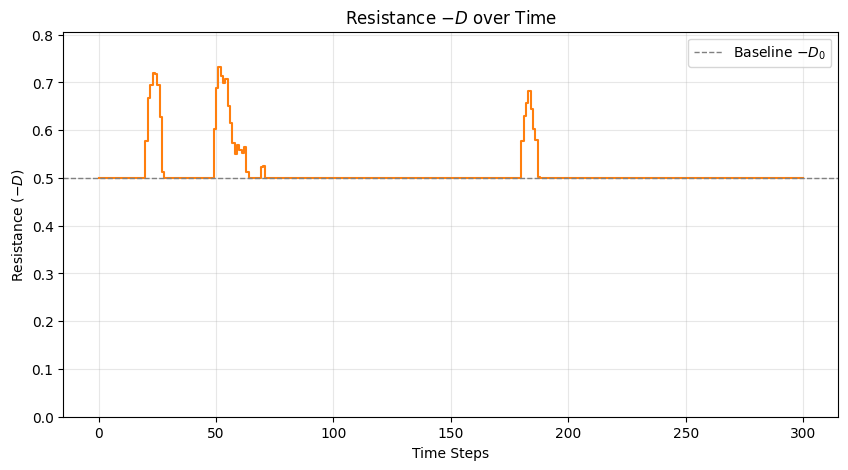

In [ ]:
# PLOT ONLY THE ACTIVE RESISTANCE (-D)
minus_D = -np.array(D_history)

plt.figure(figsize=(10, 5))
plt.step(range(len(minus_D)), minus_D, where='post', color='tab:orange')
plt.axhline(-D_initial, linestyle='--', color='gray', linewidth=1,
            label=r"Baseline $-D_0$")
plt.xlabel("Time Steps")
plt.ylabel(r"Resistance $(-D)$")
plt.title(r"Resistance $-D$ over Time")
plt.ylim(0, minus_D.max() * 1.1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

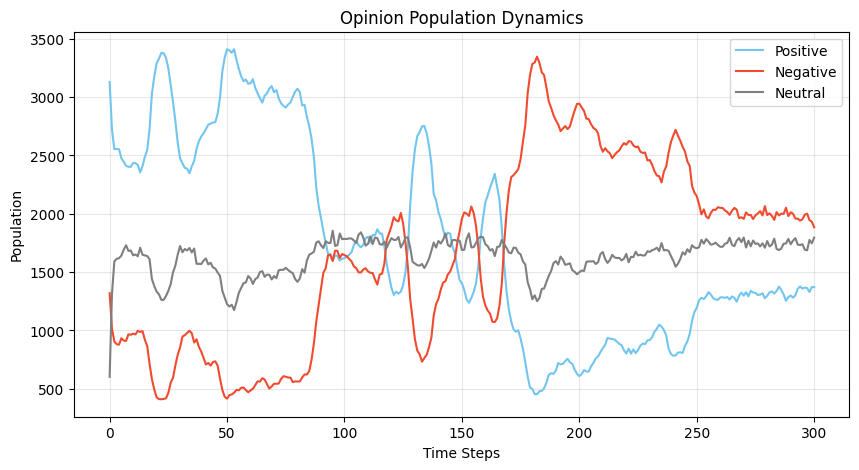

In [ ]:
# PLOT OPINION POPULATION DYNAMIC OVER TIME
plt.figure(figsize=(10, 5))
plt.plot(N_up_history, color="#72C5EF", label="Positive")
plt.plot(N_down_history, color="#F04B2F", label="Negative")
plt.plot(N_neutral_history, color="#7F7F7F", label="Neutral")
plt.xlabel("Time Steps")
plt.ylabel("Population")
plt.title("Opinion Population Dynamics")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Jump up   to the locked-in branch at h + h_ext ≈ +0.089
Drop down from the locked-in branch at h + h_ext ≈ -0.099
Hysteresis width ≈ 0.188


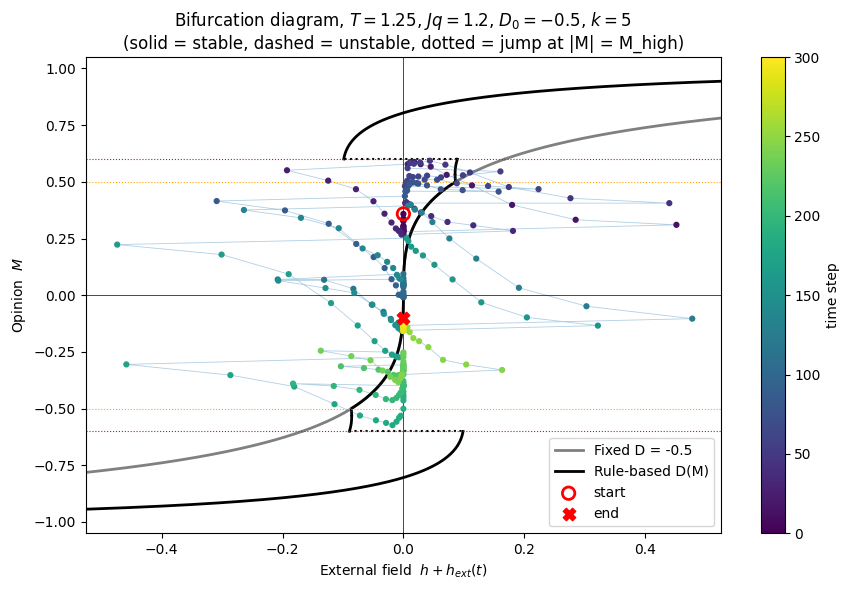

In [ ]:
# ============================================================
# BIFURCATION GRAPH: M* vs external field (h + h_ext)
# + the simulated path (h + h_ext(t), M(t)) on top
# Run AFTER the simulation cell (uses Data_M, Data_h_ext)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ------------------------- SETTINGS -------------------------
T_plot   = Temperature        # temperature used in the simulation
Jq       = J_coupling * q_neighbors   # coupling J*q
Do_plot  = D_initial          # D0
k_plot   = k_sensitivity      # k in the middle band
Mlo_plot = M_low              # low-band threshold (0.5)
Mhi_plot = M_high             # high-band threshold (0.6)

lag        = 0       # shift M by a few steps if it lags behind h (try 1-3)
show_fixed = True    # draw the fixed-D reference curve (grey)
x_range    = None    # e.g. (-0.4, 0.4); None = automatic
# ------------------------------------------------------------


# ---- your D rule (same as in the model) ----
def D_rule(M):
    a = abs(M)
    if a < Mlo_plot:
        return Do_plot
    elif a <= Mhi_plot:
        return Do_plot * (1 + k_plot * (a - Mlo_plot))
    else:
        return -np.exp(abs(Do_plot) + (a - Mhi_plot))

def D_fixed(M):
    return Do_plot


# ---- single-spin response of the restricted (A-B) heat-bath model ----
def M_single(x, D, T):
    # x = beta * h_eff
    c = np.exp(-D / T)
    num = 2*c*np.sinh(x) + 2*c**2*np.sinh(2*x)
    den = 1 + 4*c*np.cosh(x) + 2*c**2*np.cosh(2*x)
    return num / den


# ---- for a given M, find the field h that makes M a steady state ----
# self-consistency: M = M_single(beta*(h + Jq*M), D(M))
# solve for x = beta*h_eff, then h = x*T - Jq*M
def h_of_M(M, D_func):
    D = D_func(M)
    x = brentq(lambda x: M_single(x, D, T_plot) - M, -40, 40)
    return x * T_plot - Jq * M


def branch(D_func):
    # split at the thresholds so the jumps in D are not joined by a line
    edges = [-0.999, -Mhi_plot, -Mlo_plot, Mlo_plot, Mhi_plot, 0.999]
    pieces = []
    for a, b in zip(edges[:-1], edges[1:]):
        Ms = np.linspace(a, b, 400)[1:-1]
        hs = np.array([h_of_M(m, D_func) for m in Ms])
        pieces.append((hs, Ms))
    return pieces


def plot_branch(ax, D_func, color, label):
    first = True
    for hs, Ms in branch(D_func):
        dh = np.gradient(hs, Ms)
        stable = dh > 0                     # stable where h increases with M
        for mask, ls in [(stable, '-'), (~stable, '--')]:
            ax.plot(np.where(mask, hs, np.nan), np.where(mask, Ms, np.nan),
                    ls, color=color, lw=2,
                    label=label if (first and ls == '-') else None)
        first = False
    # dotted horizontal links where D jumps (|M| = M_high)
    for s in [1, -1]:
        Mth = s * Mhi_plot
        h_below = h_of_M(Mth - s*1e-4, D_func)
        h_above = h_of_M(Mth + s*1e-4, D_func)
        ax.plot([h_below, h_above], [Mth, Mth], ':', color=color, lw=1.5)


# ---- print the jump points (useful for the text) ----
h_up   = h_of_M(Mhi_plot - 1e-4, D_rule)   # lower branch ends -> jump UP
h_down = h_of_M(Mhi_plot + 1e-4, D_rule)   # upper branch ends -> drop DOWN
print(f"Jump up   to the locked-in branch at h + h_ext ≈ {h_up:+.3f}")
print(f"Drop down from the locked-in branch at h + h_ext ≈ {h_down:+.3f}")
print(f"Hysteresis width ≈ {h_up - h_down:.3f}")


# ============================ PLOT ============================
fig, ax = plt.subplots(figsize=(9, 6))

if show_fixed:
    plot_branch(ax, D_fixed, 'grey', f'Fixed D = {Do_plot}')
plot_branch(ax, D_rule, 'black', 'Rule-based D(M)')

# ---- simulated path ----
H     = External_field + np.array(h_ext_history, dtype=float)   # total external field h + h_ext
M_sim = np.array(M_history, dtype=float)
n = min(len(H), len(M_sim))
H, M_sim = H[:n], M_sim[:n]
if lag > 0:
    H, M_sim = H[:-lag], M_sim[lag:]
steps = np.arange(len(H))

ax.plot(H, M_sim, '-', color='tab:blue', lw=0.6, alpha=0.35)
sc = ax.scatter(H, M_sim, c=steps, cmap='viridis', s=12, zorder=3)
ax.scatter(H[0], M_sim[0], marker='o', s=80, facecolors='none',
           edgecolors='red', lw=2, zorder=4, label='start')
ax.scatter(H[-1], M_sim[-1], marker='X', s=80, color='red', zorder=4, label='end')
plt.colorbar(sc, ax=ax, label='time step')

# reference lines
ax.axhline(0, color='k', lw=0.5)
ax.axvline(0, color='k', lw=0.5)
for s in [1, -1]:
    ax.axhline(s*Mlo_plot, color='orange', lw=0.8, ls=':')
    ax.axhline(s*Mhi_plot, color='red',    lw=0.8, ls=':')

if x_range is None:
    hx = max(0.4, np.nanmax(np.abs(H)) * 1.1)
    x_range = (-hx, hx)
ax.set_xlim(*x_range)
ax.set_ylim(-1.05, 1.05)
ax.set_xlabel(r'External field  $h + h_{ext}(t)$')
ax.set_ylabel(r'Opinion  $M$')
ax.set_title(rf'Bifurcation diagram, $T={T_plot}$, $Jq={Jq}$, '
             rf'$D_0={Do_plot}$, $k={k_plot}$'
             '\n(solid = stable, dashed = unstable, dotted = jump at |M| = M_high)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

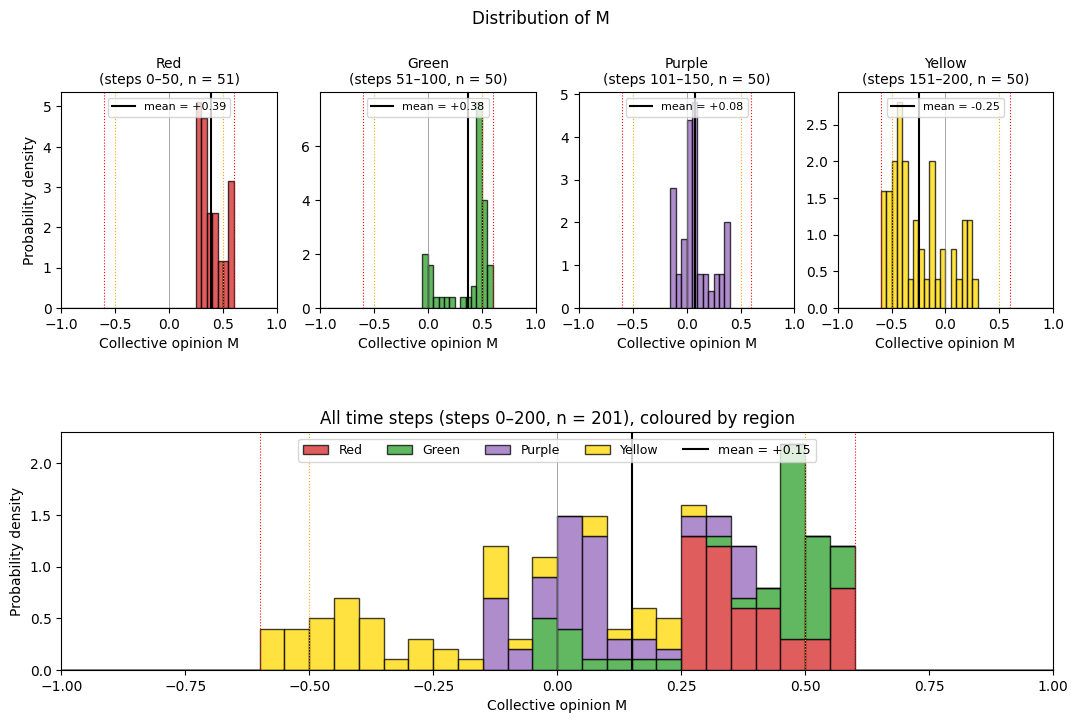

region      mean    std    min    max
Red       +0.391  0.106  +0.27  +0.59
Green     +0.375  0.204  -0.01  +0.59
Purple    +0.080  0.149  -0.13  +0.40
Yellow    -0.247  0.256  -0.57  +0.25
ALL       +0.151  0.320  -0.57  +0.59
time spent with M > +0.6: 0%,  |M| <= 0.6: 100%,  M < -0.6: 0%


In [ ]:
# ============================================================
# HISTOGRAM PER REGION + ALL TIME STEPS
# Uses M_history, N_up_history, N_neutral_history, N_down_history from your run
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# ------------------------- SETTINGS -------------------------
regions = [   # (name, first step, last step, colour)  <-- adjust to your boxes
    ('Red',     0,   50,  'tab:red'),
    ('Green',   51,  100, 'tab:green'),
    ('Purple',  101, 150, 'tab:purple'),
    ('Yellow',  151, 200, 'gold'),
]
variable = 'M'        # 'M' = collective opinion, 'p0' = share of neutrals
n_bins   = 40
# ------------------------------------------------------------

N_tot = np.array(N_up_history) + np.array(N_neutral_history) + np.array(N_down_history)
data = {'M':  np.array(M_history, dtype=float),
        'p0': np.array(N_neutral_history) / N_tot}[variable]
x_range = (-1, 1) if variable == 'M' else (0, 1)
bins = np.linspace(*x_range, n_bins + 1)
xlabel = 'Collective opinion M' if variable == 'M' else 'Share of neutrals p(0)'

def reference_lines(ax):
    if variable == 'M':
        for s in [1, -1]:
            ax.axvline(s * M_low,  color='orange', ls=':', lw=0.8)
            ax.axvline(s * M_high, color='red',    ls=':', lw=0.8)
        ax.axvline(0, color='grey', lw=0.5)

# layout: one row of region panels on top, the all-time panel below (full width)
fig = plt.figure(figsize=(3.2 * len(regions), 7.5))
gs = fig.add_gridspec(2, len(regions), height_ratios=[1, 1.1], hspace=0.55)

# ---- top: one histogram per region ----
region_data = []
for j, (name, a, b, col) in enumerate(regions):
    ax = fig.add_subplot(gs[0, j])
    b = min(b, len(data) - 1)
    x = data[a:b + 1]
    region_data.append(x)
    ax.hist(x, bins=bins, density=True, color=col, alpha=0.75, edgecolor='k', lw=0.3)
    ax.axvline(x.mean(), color='k', lw=1.5, label=f'mean = {x.mean():+.2f}')
    reference_lines(ax)
    ax.set_xlim(*x_range)
    ax.set_title(f'{name}\n(steps {a}–{b}, n = {len(x)})', fontsize=10)
    ax.set_xlabel(xlabel)
    if j == 0:
        ax.set_ylabel('Probability density')
    ax.legend(fontsize=8, loc='upper center')

# ---- bottom: all time steps, stacked by region (each colour = that region's share) ----
ax_all = fig.add_subplot(gs[1, :])
x_all = np.concatenate(region_data)
ax_all.hist(region_data, bins=bins, stacked=True, density=True,
            color=[r[3] for r in regions], alpha=0.75, edgecolor='k', lw=0.3,
            label=[r[0] for r in regions])
ax_all.axvline(x_all.mean(), color='k', lw=1.5, label=f'mean = {x_all.mean():+.2f}')
reference_lines(ax_all)
ax_all.set_xlim(*x_range)
ax_all.set_xlabel(xlabel); ax_all.set_ylabel('Probability density')
ax_all.set_title(f'All time steps (steps {regions[0][1]}–{min(regions[-1][2], len(data)-1)}, '
                 f'n = {len(x_all)}), coloured by region')
ax_all.legend(fontsize=9, loc='upper center', ncol=len(regions) + 1)

fig.suptitle(f'Distribution of {variable}', y=0.99)
plt.show()

# ---- numbers for the text ----
print(f"{'region':8s} {'mean':>7s} {'std':>6s} {'min':>6s} {'max':>6s}")
for (name, *_), x in zip(regions, region_data):
    print(f"{name:8s} {x.mean():+7.3f} {x.std():6.3f} {x.min():+6.2f} {x.max():+6.2f}")
print(f"{'ALL':8s} {x_all.mean():+7.3f} {x_all.std():6.3f} {x_all.min():+6.2f} {x_all.max():+6.2f}")
if variable == 'M':
    print(f"time spent with M > +{M_high}: {np.mean(x_all > M_high):.0%},  "
          f"|M| <= {M_high}: {np.mean(np.abs(x_all) <= M_high):.0%},  "
          f"M < -{M_high}: {np.mean(x_all < -M_high):.0%}")

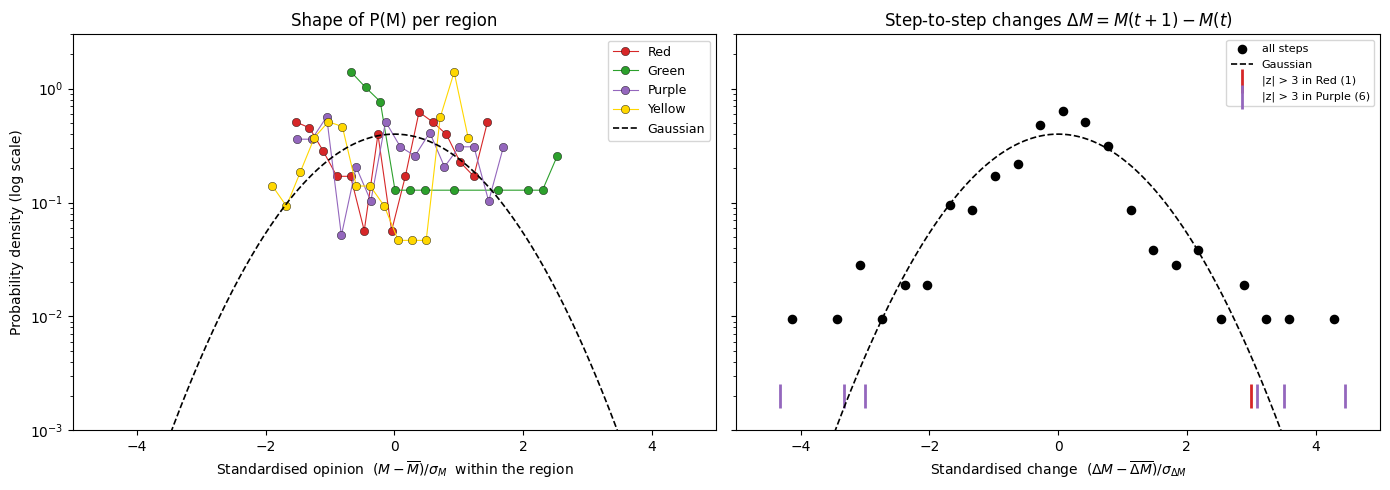

              n    mean    std   skew  ex.kurt
M  Red       83  +0.435  0.102  -0.19    -1.33
M  Green     34  +0.099  0.136  +1.61    +1.25
M  Purple    85  -0.112  0.283  +0.04    -1.15
M  Yellow    99  -0.232  0.104  -0.34    -1.50
dM all      300  -0.002  0.029  -0.02    +3.61
largest |dM| = 0.129 between steps 127 and 128 (4.5 std)


In [ ]:
# ============================================================
# DISTRIBUTION SHAPE AS SCATTER (log scale) + GAUSSIAN REFERENCE
# Left : P(M) of each region, standardised  z = (M - mean)/std  -> compare shapes
# Right: P(dM) of the step-to-step changes dM = M(t+1) - M(t), standardised
#        -> this is where heavy tails (big sudden jumps) show up
# Dashed line = standard normal (Gaussian). Dots above it far from 0 = heavier tails.
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------- SETTINGS -------------------------
regions = [   # (name, first step, last step, colour)
    ('Red',     0,   82,  'tab:red'),
    ('Green',   83,  116, 'tab:green'),
    ('Purple',  117, 201, 'tab:purple'),
    ('Yellow',  202, 300, 'gold'),
]
n_bins_M  = 15        # few points per region -> keep bins coarse
n_bins_dM = 25
z_lim     = 5         # x-range in standard deviations
# ------------------------------------------------------------

M_arr = np.array(M_history, dtype=float)

def density_points(x, bins):
    p, edges = np.histogram(x, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    keep = p > 0                      # log scale: drop empty bins
    return centers[keep], p[keep]

def standardise(x):
    return (x - x.mean()) / x.std()

zs = np.linspace(-z_lim, z_lim, 400)
fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# ---- left: shape of P(M) in each region ----
for name, a, b, col in regions:
    b = min(b, len(M_arr) - 1)
    z = standardise(M_arr[a:b + 1])
    c, p = density_points(z, np.linspace(z.min(), z.max(), n_bins_M + 1))
    axL.plot(c, p, 'o-', color=col, ms=6, mec='k', mew=0.3, lw=0.8, label=name)
axL.plot(zs, stats.norm.pdf(zs), 'k--', lw=1.2, label='Gaussian')
axL.set_yscale('log'); axL.set_ylim(1e-3, 3); axL.set_xlim(-z_lim, z_lim)
axL.set_xlabel(r'Standardised opinion  $(M - \overline{M})/\sigma_M$  within the region')
axL.set_ylabel('Probability density (log scale)')
axL.set_title('Shape of P(M) per region')
axL.legend(fontsize=9)

# ---- right: step-to-step changes, all steps ----
dM = np.diff(M_arr)                 # dM[i] = M(i+1) - M(i)
z = standardise(dM)
c, p = density_points(z, np.linspace(z.min(), z.max(), n_bins_dM + 1))
axR.scatter(c, p, color='k', s=35, zorder=3, label=r'all steps')
axR.plot(zs, stats.norm.pdf(zs), 'k--', lw=1.2, label='Gaussian')
# mark the big jumps (|z| > 3), coloured by the region they happened in
for name, a, b, col in regions:
    idx = np.arange(a, min(b, len(z)))
    big = idx[np.abs(z[idx]) > 3]
    if len(big):
        axR.scatter(z[big], np.full(len(big), 2e-3), marker='|', s=300, color=col,
                    lw=2, label=f'|z| > 3 in {name} ({len(big)})')
axR.set_xlim(-z_lim, z_lim)
axR.set_xlabel(r'Standardised change  $(\Delta M - \overline{\Delta M})/\sigma_{\Delta M}$')
axR.set_title(r'Step-to-step changes $\Delta M = M(t+1) - M(t)$')
axR.legend(fontsize=8)

plt.tight_layout(); plt.show()

# ---- numbers for the text ----
# excess kurtosis: 0 = Gaussian, > 0 = heavier tails, < 0 = lighter tails / flatter
print(f"{'':10s} {'n':>4s} {'mean':>7s} {'std':>6s} {'skew':>6s} {'ex.kurt':>8s}")
for name, a, b, _ in regions:
    b = min(b, len(M_arr) - 1)
    x = M_arr[a:b + 1]
    print(f"M  {name:7s} {len(x):4d} {x.mean():+7.3f} {x.std():6.3f} "
          f"{stats.skew(x):+6.2f} {stats.kurtosis(x):+8.2f}")
print(f"dM {'all':7s} {len(dM):4d} {dM.mean():+7.3f} {dM.std():6.3f} "
      f"{stats.skew(dM):+6.2f} {stats.kurtosis(dM):+8.2f}")
k = np.argmax(np.abs(dM))
print(f"largest |dM| = {abs(dM[k]):.3f} between steps {k} and {k+1} ({abs(z[k]):.1f} std)")

__INTERACTIVE OUTPUT SECTION__

In [ ]:
#DYNAMIC MAP OF THE LATTICE
from IPython.display import HTML, display
import json
import numpy as np

# Prepare spin data
spin_data = [np.asarray(s).tolist() for s in spin_history]

M_data = np.asarray(M_history).tolist()
N_data = np.asarray(N_total_history).tolist()

html = f"""
<div style="font-family: Arial; width: 650px;">

    <h3>Dynamic Ising Opinion Evolution Map</h3>

    <canvas id="opinionCanvas"
            width="600"
            height="600"
            style="border:1px solid black;">
    </canvas>

    <br><br>

    <input
        type="range"
        id="timeSlider"
        min="0"
        max="{len(spin_data)-1}"
        value="0"
        step="1"
        style="width:600px;"
    >

    <br><br>

    <button id="playButton">
        ▶ Play
    </button>

    <p>
        MCS:
        <span id="mcsValue">0</span>
        &nbsp;&nbsp;&nbsp;

        M:
        <span id="magValue">---</span>

        &nbsp;&nbsp;&nbsp;

        N:
        <span id="NValue">---</span>
    </p>

</div>

<script>

(function(){{

    const spinData = {json.dumps(spin_data)};
    const magnetization = {json.dumps(M_data)};
    const population = {json.dumps(N_data)};

    const canvas = document.getElementById("opinionCanvas");
    const ctx = canvas.getContext("2d");

    const slider = document.getElementById("timeSlider");
    const playButton = document.getElementById("playButton");

    const mcsText = document.getElementById("mcsValue");
    const magText = document.getElementById("magValue");
    const NText = document.getElementById("NValue");

    let playing = false;
    let animationTimer = null;

    // =========================
    // Draw map
    // =========================

    function drawMap(mcs) {{

        const spins = spinData[mcs];

        const N = spins.length;

        const gridSize = Math.ceil(Math.sqrt(N));

        ctx.clearRect(
            0,
            0,
            canvas.width,
            canvas.height
        );

        ctx.fillStyle = "white";

        ctx.fillRect(
            0,
            0,
            canvas.width,
            canvas.height
        );

        const cellSize = canvas.width / gridSize;

        for (let i = 0; i < N; i++) {{

            const row = Math.floor(i / gridSize);
            const col = i % gridSize;

            const x = col * cellSize;
            const y = row * cellSize;

            const spin = spins[i];
            if (spin === 1) {{
                ctx.fillStyle = "#73C5EF";
            }}
            else if (spin === -1) {{
                ctx.fillStyle = "#F04B2F";
            }}
            else {{
                ctx.fillStyle = "#7F7F7F";
            }}

            ctx.fillRect(
                x,
                y,
                cellSize,
                cellSize
            );
        }}

        // Display information

        mcsText.textContent = mcs;

        if (mcs < magnetization.length) {{
            magText.textContent =
                magnetization[mcs].toFixed(4);
        }}
        else {{
            magText.textContent = "---";
        }}

        if (mcs < population.length) {{
            NText.textContent = population[mcs];
        }}
        else {{
            NText.textContent = "---";
        }}
    }}

    // =========================
    // Slider
    // =========================

    slider.addEventListener(
        "input",
        function() {{
            drawMap(parseInt(this.value));
        }}
    );

    // =========================
    // Play / Pause
    // =========================

    playButton.addEventListener(
        "click",
        function() {{

            if (playing) {{

                playing = false;

                clearInterval(animationTimer);

                playButton.textContent = "▶ Play";

            }} else {{

                playing = true;

                playButton.textContent = "⏸ Pause";

                animationTimer = setInterval(
                    function() {{

                        let current =
                            parseInt(slider.value);

                        if (current >= spinData.length - 1) {{

                            playing = false;

                            clearInterval(animationTimer);

                            playButton.textContent = "▶ Play";

                            return;
                        }}

                        current += 1;

                        slider.value = current;

                        drawMap(current);

                    }},
                    50
                );
            }}
        }}
    );

    // =========================
    // Initial map
    // =========================

    drawMap(0);

}})();

</script>
"""

display(HTML(html))